# Klasyfikacja jakości powietrza

Analiza czterech klas oraz binarnego grupowania etykiet. Notebook korzysta z wyników zapisanych przez kompletny eksperyment.

Pełne przeliczenie: `python -m air_quality run --config configs/study.json`. Nie dobieramy modeli na zbiorze testowym.

In [1]:
import json
from pathlib import Path
import pandas as pd
from IPython.display import SVG, display
from air_quality.data import load_dataset, audit_dataset

ROOT = next(path for path in (Path.cwd(), *Path.cwd().parents) if (path / 'pyproject.toml').exists())
OUTPUT = ROOT / 'reports'
data = load_dataset(ROOT / 'data/raw/pollution_dataset.csv')
audit = audit_dataset(data)
manifest = json.loads((OUTPUT / 'run_manifest.json').read_text())
assert manifest['evaluation_status'] == 'completed'
display(data.head())

,Temperature,Humidity,PM2.5,PM10,NO2,SO2,CO,Proximity_to_Industrial_Areas,Population_Density,Air Quality
0,29.8,59.1,5.2,17.9,18.9,9.2,1.72,6.3,319.0,Moderate
1,28.3,75.6,2.3,12.2,30.8,9.7,1.64,6.0,611.0,Moderate
2,23.1,74.7,26.7,33.8,24.4,12.6,1.63,5.2,619.0,Moderate
3,27.1,39.1,6.1,6.3,13.5,5.3,1.15,11.1,551.0,Good
4,26.5,70.7,6.9,16.0,21.9,5.6,1.01,12.7,303.0,Good


## Dane i zakres wnioskowania

Źródło: Mujtaba Mateen, Kaggle, wersja 2, Apache 2.0. Dokumentacja nie podaje stacji, dat, procedury zbierania danych ani reguły etykietowania. Nie potwierdza pochodzenia z WHO/Banku Światowego ani rzeczywistego lub syntetycznego charakteru obserwacji.

,class,rows,any_issue_rows,hard_issue_rows,issue_rate
0,Good,2000,32,17,0.016
1,Moderate,1500,15,7,0.010
2,Poor,1000,72,70,0.072
3,Hazardous,500,135,131,0.270


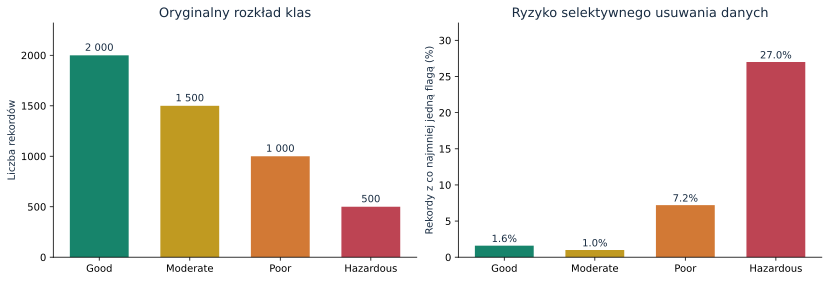

In [2]:
display(pd.DataFrame(audit['issues_by_class']))
display(SVG(filename=str(OUTPUT / 'figures/data_quality.svg')))

## Protokół oceny

Wspólny podział stratyfikowany według czterech klas, 80% development / 20% test. Pipeline: reguły domenowe, imputacja medianą, skalowanie, opcjonalny SMOTE, model. Przetwarzanie jest dopasowywane osobno w każdym foldzie. Klasa dodatnia w zadaniu binarnym: Poor lub Hazardous.

In [3]:
display(pd.DataFrame(manifest['config'].items(), columns=['Setting', 'Value']))
split = pd.read_csv(OUTPUT / 'tables/split_manifest.csv')
display(pd.crosstab(split['original_class'], split['partition']))

,Setting,Value
0,profile,full
1,dataset,data/raw/pollution_dataset.csv
2,output_dir,reports
3,expected_sha256,052fc6679ac05ef51e9198cb80b7e944ea134a04ad07b8...
4,split_seed,42
5,cv_seed,19
6,model_seed,42
7,bootstrap_seed,2026
8,test_size,0.2
9,outer_splits,5


partition,development,holdout
original_class,,
Good,1600,400
Hazardous,400,100
Moderate,1200,300
Poor,800,200


## EDA części treningowej

Pełny zbiór służy wyłącznie audytowi schematu i jakości. Poniższe rozkłady i korelacje dotyczą części development.

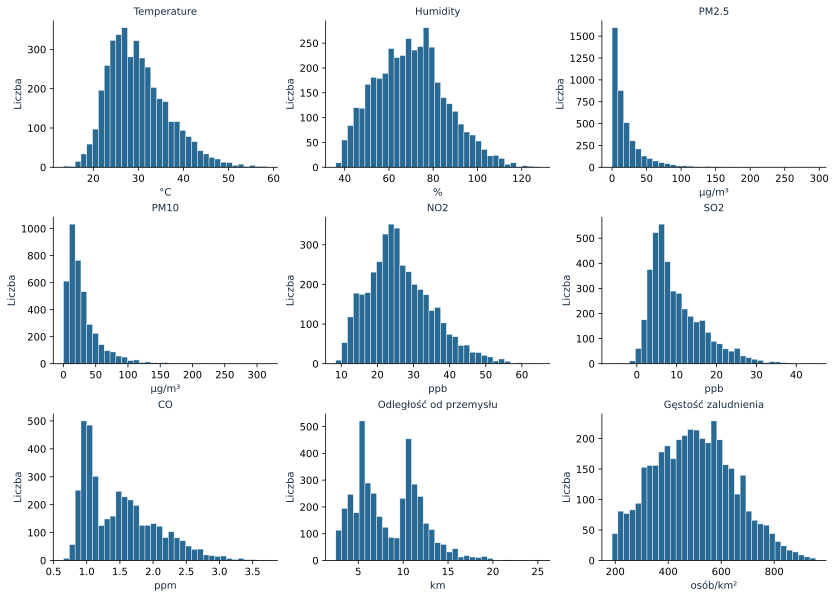

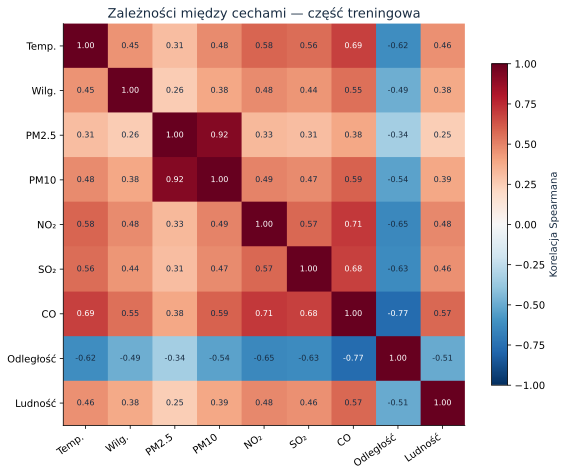

In [4]:
display(SVG(filename=str(OUTPUT / 'figures/development_distributions.svg')))
display(SVG(filename=str(OUTPUT / 'figures/correlation.svg')))

## Porównanie modeli

Wyniki `nested_tuned` pochodzą z zewnętrznych foldów, a hiperparametry wybierano w wewnętrznej walidacji. SD foldów nie jest przedziałem ufności. Wybór najlepszej rodziny na podstawie tych wyników wprowadza dodatkową selekcję.

multiclass
binary


,model,procedure,macro_f1_mean,macro_f1_std,accuracy_mean,balanced_accuracy_mean,train_macro_f1_mean,fit_seconds_mean
0,dummy,baseline,0.142857,0.000000,0.40000,0.250000,0.142857,0.037574
1,logistic,baseline,0.910820,0.008688,0.93875,0.905885,0.915360,0.057697
2,logistic,nested_tuned,0.911253,0.009937,0.93900,0.907031,0.916758,1.294113
3,knn,baseline,0.877486,0.013890,0.91825,0.862083,1.000000,0.119500
4,knn,nested_tuned,0.889206,0.014480,0.92325,0.888802,0.946444,1.466330
5,svm,baseline,0.916390,0.003173,0.94375,0.912865,0.942680,0.401420
6,svm,nested_tuned,0.916461,0.004702,0.94450,0.914531,0.937218,6.267413
7,random_forest,baseline,0.930168,0.008944,0.95325,0.925104,1.000000,0.997044
8,random_forest,nested_tuned,0.929387,0.009481,0.95300,0.924063,0.995628,31.275242
9,hist_boosting,baseline,0.933221,0.004013,0.95500,0.928854,1.000000,0.827293


,model,procedure,macro_f1_mean,macro_f1_std,accuracy_mean,balanced_accuracy_mean,train_macro_f1_mean,fit_seconds_mean
0,dummy,baseline,0.411765,0.000000,0.70000,0.500000,0.411765,0.025410
1,logistic,baseline,0.966109,0.011233,0.97175,0.962917,0.968078,0.033283
2,logistic,nested_tuned,0.967635,0.010425,0.97300,0.965000,0.968723,0.648763
3,knn,baseline,0.958106,0.009687,0.96575,0.946726,1.000000,0.132015
4,knn,nested_tuned,0.965428,0.012205,0.97100,0.965476,0.994010,1.906205
5,svm,baseline,0.969478,0.008839,0.97450,0.967024,0.977108,0.294260
6,svm,nested_tuned,0.968324,0.008300,0.97350,0.966310,0.977018,5.111456
7,random_forest,baseline,0.977916,0.004304,0.98150,0.976786,1.000000,1.236501
8,random_forest,nested_tuned,0.977916,0.004304,0.98150,0.976786,1.000000,30.801530
9,hist_boosting,baseline,0.974568,0.006519,0.97875,0.972440,1.000000,0.262904


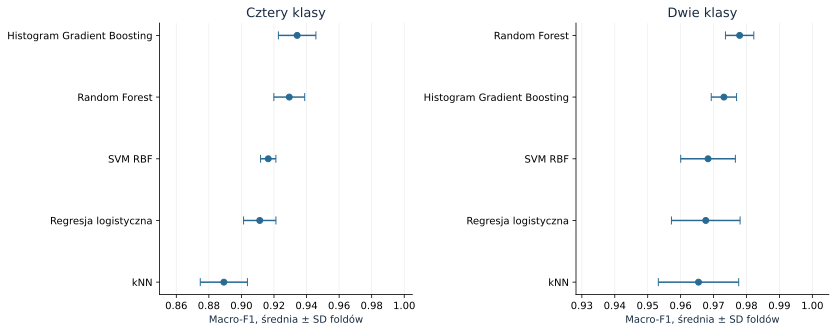

In [5]:
for task in ('multiclass', 'binary'):
    print(task)
    display(pd.read_csv(OUTPUT / 'tables' / f'{task}_cv_summary.csv'))
display(SVG(filename=str(OUTPUT / 'figures/nested_cv.svg')))

## Eksperymenty wrażliwości

Równoważenie porównano dla regresji logistycznej. Grupy cech, czyszczenie i odległości do klastrów porównano dla ustalonego Histogram Gradient Boosting. Eksperymenty opisowe nie zmieniają głównej procedury wyboru modelu.

,experiment,treatment,reference_model,macro_f1_mean,macro_f1_std,balanced_accuracy_mean
0,balancing,none,logistic,0.910820,0.008688,0.905885
1,balancing,class_weights,logistic,0.910716,0.008786,0.914323
2,balancing,smote,logistic,0.912675,0.009191,0.915156
3,features,all_features,hist_boosting,0.933221,0.004013,0.928854
4,features,pollutants_only,hist_boosting,0.855202,0.010995,0.850365
5,features,context_only,hist_boosting,0.808395,0.016658,0.801042
6,features,without_CO,hist_boosting,0.893656,0.009259,0.888073
7,features,without_PM2.5,hist_boosting,0.930521,0.007158,0.927396
8,features,cluster_distances,hist_boosting,0.930834,0.011364,0.927188
9,cleaning,raw_values,hist_boosting,0.931894,0.009523,0.928125


,experiment,treatment,reference_model,macro_f1_mean,macro_f1_std,balanced_accuracy_mean
0,balancing,none,logistic,0.966109,0.011233,0.962917
1,balancing,class_weights,logistic,0.961962,0.005732,0.966488
2,balancing,smote,logistic,0.965087,0.007710,0.967976
3,features,all_features,hist_boosting,0.974568,0.006519,0.972440
4,features,pollutants_only,hist_boosting,0.948204,0.007367,0.943333
5,features,context_only,hist_boosting,0.915942,0.010432,0.905893
6,features,without_CO,hist_boosting,0.955838,0.006394,0.951845
7,features,without_PM2.5,hist_boosting,0.973395,0.005234,0.971726
8,features,cluster_distances,hist_boosting,0.976065,0.006479,0.973810
9,cleaning,raw_values,hist_boosting,0.975186,0.005079,0.973274


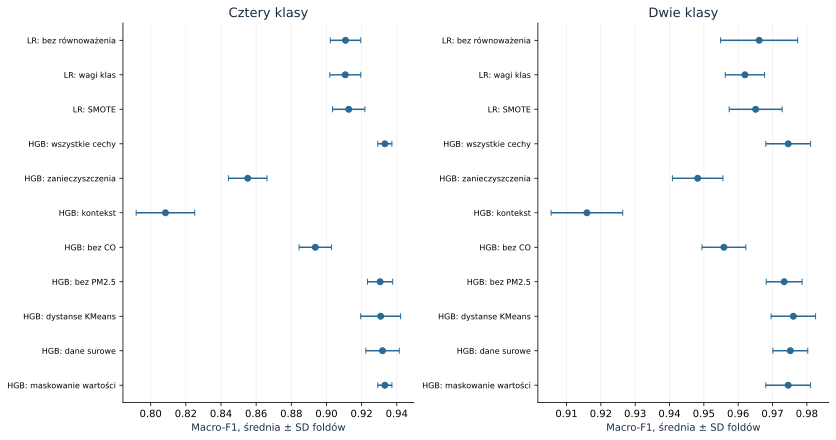

In [6]:
for task in ('multiclass', 'binary'):
    display(pd.read_csv(OUTPUT / 'tables' / f'{task}_ablation_summary.csv'))
display(SVG(filename=str(OUTPUT / 'figures/ablations.svg')))

## Zamrożone decyzje i ocena końcowa

Modele i progi F2 wybrano przed oceną testową. Porównujemy model binarny z sumą P(Poor) + P(Hazardous), stosując wspólny cel binarny. Przedziały bootstrap dotyczą niepewności próby testowej przy stałych modelach.

{'multiclass': {'name': 'hist_boosting',
  'params': {'model__max_leaf_nodes': 7,
   'model__learning_rate': 0.05,
   'model__l2_regularization': 0.0,
   'model__class_weight': None,
   'balance': 'passthrough'},
  'nested_macro_f1_mean': 0.9342196587922226,
  'nested_macro_f1_std': 0.01151680545947545},
 'binary': {'name': 'random_forest',
  'params': {'model__min_samples_leaf': 3,
   'model__max_features': 'sqrt',
   'model__class_weight': None,
   'balance': 'passthrough'},
  'nested_macro_f1_mean': 0.9779156911396745,
  'nested_macro_f1_std': 0.004304050117649238}}

,procedure,accuracy,macro_f1,balanced_accuracy,log_loss,quadratic_kappa,ordinal_mae,severe_error_rate,positive_f1,positive_f2,positive_precision,positive_recall,average_precision,roc_auc,brier
0,multiclass,0.961,0.942592,0.937500,0.115243,0.980253,0.039,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,binary_direct_default,0.979,0.974928,0.973571,0.068894,NaN,NaN,NaN,0.964824,0.961924,0.969697,0.960000,0.993151,0.996171,0.017712
2,binary_aggregated_default,0.983,0.979704,0.978333,0.052800,NaN,NaN,NaN,0.971524,0.968604,0.976431,0.966667,0.994546,0.997157,0.014229
3,binary_direct_f2,0.970,0.964874,0.972857,0.068894,NaN,NaN,NaN,0.951456,0.968379,0.924528,0.980000,0.993151,0.996171,0.017712
4,binary_aggregated_f2,0.976,0.971642,0.975238,0.052800,NaN,NaN,NaN,0.960526,0.968170,0.948052,0.973333,0.994546,0.997157,0.014229


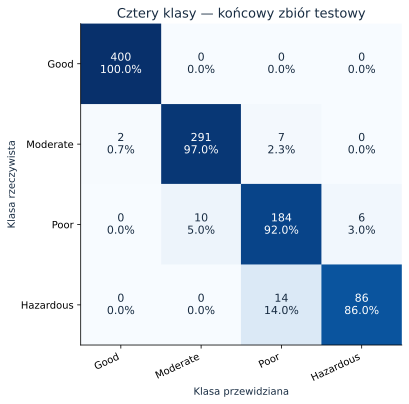

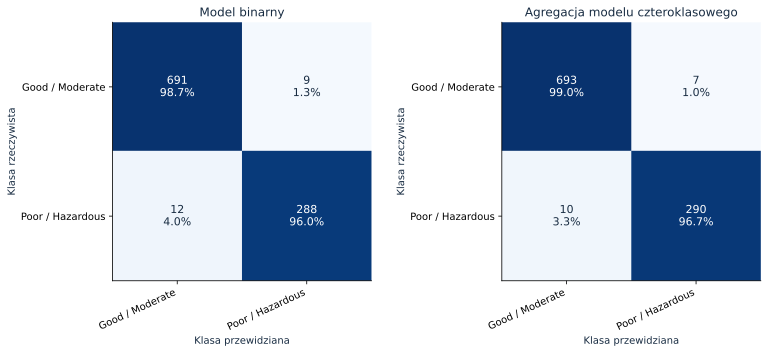

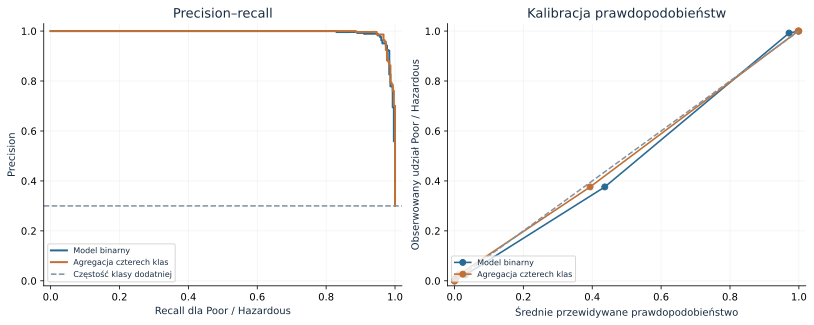

{'macro_f1_delta_direct_minus_aggregated': -0.004775600501915722,
 'paired_95ci': [-0.011838393025907062, 0.0011712528294828882],
 'mcnemar_exact_p': 0.2890625,
 'direct_only_correct': 2,
 'aggregated_only_correct': 6,
 'interpretation': 'McNemar tests paired correctness, not equality of macro-F1.'}

In [7]:
decisions = json.loads((OUTPUT / 'frozen_decisions.json').read_text())
results = json.loads((OUTPUT / 'holdout_metrics.json').read_text())
display(decisions['models'])
rows = [{'procedure': name, **{key: value for key, value in result.items() if isinstance(value, (float, int))}} for name, result in results.items() if name != 'paired_binary_comparison']
display(pd.DataFrame(rows))
display(SVG(filename=str(OUTPUT / 'figures/multiclass_confusion.svg')))
display(SVG(filename=str(OUTPUT / 'figures/binary_confusion.svg')))
display(SVG(filename=str(OUTPUT / 'figures/probability_quality.svg')))
display(results['paired_binary_comparison'])

## Interpretacja i ograniczenia

Permutation importance opisuje wrażliwość predykcji, a nie przyczynowość. Skorelowane cechy mogą dzielić znaczenie. PDP może tworzyć nierealistyczne kombinacje cech. Jakość na tym zbiorze nie dowodzi skuteczności w innych miastach, okresach ani zastosowaniach zdrowotnych.

,feature,importance_mean,importance_std
0,Temperature,0.032964,0.005430
1,Humidity,0.026811,0.006074
2,PM2.5,0.008675,0.001355
3,PM10,0.017896,0.005211
4,NO2,0.049572,0.005621
5,SO2,0.022890,0.004878
6,CO,0.298183,0.013738
7,Proximity_to_Industrial_Areas,0.261250,0.011501
8,Population_Density,0.027424,0.006257


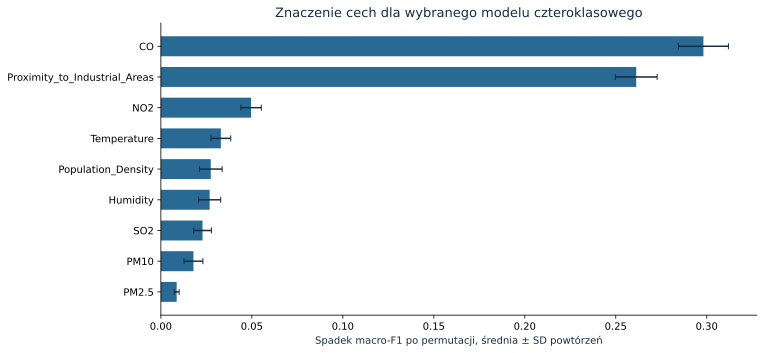

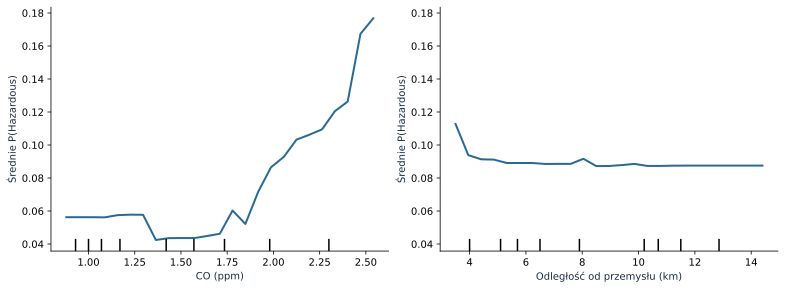

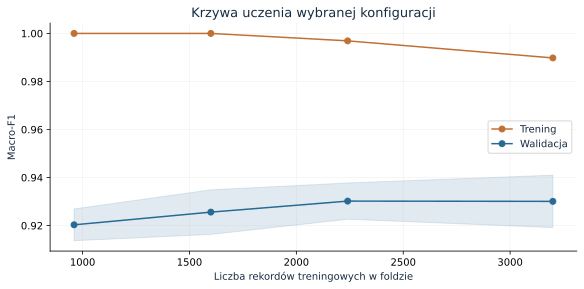

In [8]:
display(pd.read_csv(OUTPUT / 'tables/permutation_importance.csv'))
display(SVG(filename=str(OUTPUT / 'figures/permutation_importance.svg')))
display(SVG(filename=str(OUTPUT / 'figures/partial_dependence.svg')))
curve = OUTPUT / 'figures/learning_curve.svg'
if curve.exists():
    display(SVG(filename=str(curve)))